# Día 4 — Clustering: segmentar clientes de tarjeta de crédito

**Módulo 3: Machine Learning Aplicado — CEC EPN / Banco Central del Ecuador**

Hasta ahora siempre conocíamos la respuesta `y`. Hoy **no hay respuesta**: tenemos 8 950 clientes de tarjeta de crédito y queremos descubrir **grupos de clientes que se comportan parecido**.

## Cómo está organizado

| Paso | Qué hacemos |
|---|---|
| 1. Mirar los datos | Cargar, `head`, tipos y resumen |
| 2. Entender y graficar | Qué es una fila, cómo se distribuyen las variables |
| 3. Limpiar y preparar | Faltantes, logaritmo y escalado, **paso a paso con el antes y el después** |
| 4. Dividir | Train y Validation, para comprobar que los grupos se sostienen con clientes nuevos |
| 5. K-Means a mano | Con 12 clientes y una sola variable |
| 6. K-Means simple con scikit-learn | Pocas líneas, comentadas |
| 7. Métricas a mano y con scikit-learn | Inercia y Silhouette, en Train y en Validation |
| 8. Los hiperparámetros, uno por uno | Qué hace cada uno |
| 9. Probar combinaciones con `for` | Varios `k` y preparaciones, contra una línea base |
| 10. Modelo final | Perfiles de los grupos y qué hacer con ellos |
| 11. Clustering jerárquico | El mismo recorrido: a mano, simple, hiperparámetros, `for` |
| 12. Comparación final | Todos los métodos en todos los datasets del día |

## El dataset

**Credit Card Dataset for Clustering** (Kaggle, autor Arjun Bhasin). Cada fila es un cliente activo de tarjeta de crédito con su comportamiento de los últimos 6 meses. No trae ninguna etiqueta de grupo. Los montos están en dólares; no describe a clientes del Ecuador.

## Antes de empezar: aprendizaje supervisado y no supervisado

El Machine Learning tiene dos grandes familias.

**Aprendizaje supervisado** (Días 1 a 3). Es como estudiar con un profesor que entrega los ejercicios ya resueltos: cada fila de entrenamiento trae las características `X` **y la respuesta** `y`. El modelo aprende la relación entre ambas y luego predice `y` para filas nuevas. Como la respuesta existe, podemos medir exactamente cuánto se equivoca: MAE si `y` es un número (regresión), F1 si `y` es una clase (clasificación).

**Aprendizaje no supervisado** (desde hoy). Es como recibir una caja con miles de fotos sin etiquetas y ordenarlas por parecido: las filas solo traen características, **no hay `y`**. El algoritmo busca estructura por sí solo y nosotros interpretamos lo que encontró. Tareas típicas: **clustering** (agrupar filas parecidas, hoy), **reducción de dimensiones** (resumir muchas variables en pocas, PCA, Día 5) y **detección de casos raros**. Como no hay respuesta correcta, se evalúa la coherencia, la estabilidad y la utilidad de lo encontrado.

| | Supervisado | No supervisado |
|---|---|---|
| ¿Los datos traen `y`? | Sí | **No** |
| ¿Qué aprende? | A predecir `y` a partir de `X` | Estructura: grupos o patrones |
| Tareas | Regresión, clasificación | Clustering, reducción de dimensiones, casos raros |
| Algoritmos del módulo | Lineal, árboles, bosque, KNN, SVM | K-Means, jerárquico, PCA |
| Cómo se evalúa | Error frente a la respuesta real (MAE, F1) | Silhouette, estabilidad e interpretación |
| Riesgo típico | Memorizar Train (sobreajuste) | Grupos sin significado: el algoritmo siempre entrega grupos |
| Ejemplo bancario | ¿Este cliente abandonará la tarjeta? | ¿Qué tipos de clientes tenemos? |

**La pregunta clave:** ¿mis datos históricos traen la respuesta que quiero obtener? Si sí, es supervisado; si no, no supervisado.

**Practica.** ¿Supervisado o no supervisado?

1. Estimar el monto de crédito que pedirá un cliente, con historial de montos → supervisado (regresión).
2. Detectar fraude con transacciones ya marcadas como fraude o normal → supervisado (clasificación).
3. Agrupar provincias según sus indicadores económicos → no supervisado (clustering).
4. Encontrar transacciones raras cuando nadie sabe cuáles son fraude → no supervisado (casos raros).

*Cuidado:* KNN (Día 3, supervisado) y K-Means (hoy, no supervisado) se parecen en el nombre y en que usan distancias, pero resuelven problemas distintos.

## ¿Qué es clustering?

En **clasificación** el dataset ya trae la clase de cada fila (fraude o normal) y el modelo aprende a reproducirla. En **clustering** no hay clase: el algoritmo agrupa filas que se parecen según las variables que **nosotros** elegimos. Por eso se llama aprendizaje **no supervisado**: nadie le dice al algoritmo cuál es la respuesta correcta.

| | Regresión | Clasificación | Clustering |
|---|---|---|---|
| ¿Hay variable objetivo `y`? | Sí, un número | Sí, una clase | **No** |
| Pregunta | ¿Cuánto? | ¿Cuál clase? | ¿Qué grupos de filas parecidas hay? |
| Cómo se evalúa | MAE, RMSE, R² | Matriz de confusión, F1 | Silhouette, tamaños e **interpretación** |
| Ejemplo bancario | Monto que transará un cliente | ¿Abandonará la tarjeta? | Perfiles de uso de la tarjeta |

**Vocabulario.** *Cluster*: un grupo propuesto por el algoritmo. *Centroide*: el punto promedio de un grupo. *Distancia*: qué tan diferentes son dos filas. *Inercia*: suma de las distancias al cuadrado de cada fila a su centroide. *Silhouette*: qué tan bien separado está cada punto de los otros grupos.

**Dos familias de clustering.** **K-Means** agrupa alrededor de centros: decidimos antes cuántos grupos queremos (`k`) y cada fila va al centro más cercano; es rápido incluso con millones de filas. El **clustering jerárquico** construye un árbol de uniones: cada fila empieza sola y se van juntando las más parecidas; el número de grupos se elige al final, cortando el árbol. Los dos usan distancias, así que los dos necesitan datos limpios y escalados.

**Advertencia central.** Un algoritmo de clustering **siempre** entrega grupos, aunque los datos no tengan grupos reales. El valor está en que los grupos se puedan **describir, explicar y usar**; no en un número alto.

# 0. Librerías

En algunos equipos con Windows y Anaconda, K-Means muestra avisos de memoria o de núcleos del procesador. Fijamos un hilo **antes** de importar scikit-learn para evitarlos; no cambia los resultados.

In [1]:
import os
os.environ["LOKY_MAX_CPU_COUNT"] = "1"
os.environ["OMP_NUM_THREADS"] = "1"

from pathlib import Path
import numpy as np                      # cálculos numéricos
import pandas as pd                     # tablas
import matplotlib.pyplot as plt         # gráficos
from sklearn.model_selection import train_test_split               # dividir en Train y Validation
from sklearn.preprocessing import StandardScaler                   # estandarizar
from sklearn.cluster import KMeans, AgglomerativeClustering        # K-Means y jerárquico
from sklearn.metrics import silhouette_score, silhouette_samples, adjusted_rand_score
from scipy.cluster.hierarchy import linkage, dendrogram            # dibujar el dendrograma

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
DATA_DIR = Path("datos") if Path("datos").is_dir() else Path("../datos")
ARCHIVO = DATA_DIR / "CC_GENERAL.csv"
print("Archivo:", ARCHIVO.resolve())

Archivo: C:\Users\Usuario iTC\Desktop\modulo3_ml\datos\CC_GENERAL.csv


# 1. Mirar los datos

In [2]:
cc = pd.read_csv(ARCHIVO)
print("Filas y columnas:", cc.shape)
cc.head()

Filas y columnas: (8950, 18)


,CUST_ID,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE
0,C10001,40.900749,0.818182,95.40,0.00,95.4,0.000000,0.166667,0.000000,0.083333,0.000000,0,2,1000.0,201.802084,139.509787,0.000000,12
1,C10002,3202.467416,0.909091,0.00,0.00,0.0,6442.945483,0.000000,0.000000,0.000000,0.250000,4,0,7000.0,4103.032597,1072.340217,0.222222,12
2,C10003,2495.148862,1.000000,773.17,773.17,0.0,0.000000,1.000000,1.000000,0.000000,0.000000,0,12,7500.0,622.066742,627.284787,0.000000,12
3,C10004,1666.670542,0.636364,1499.00,1499.00,0.0,205.788017,0.083333,0.083333,0.000000,0.083333,1,1,7500.0,0.000000,NaN,0.000000,12
4,C10005,817.714335,1.000000,16.00,16.00,0.0,0.000000,0.083333,0.083333,0.000000,0.000000,0,1,1200.0,678.334763,244.791237,0.000000,12


| Columna | Qué es |
|---|---|
| `CUST_ID` | Identificador del cliente (no se usa para agrupar) |
| `BALANCE` | Saldo adeudado en la tarjeta |
| `BALANCE_FREQUENCY` | Qué tan seguido se actualiza el saldo (0 a 1) |
| `PURCHASES` | Total de compras en 6 meses |
| `ONEOFF_PURCHASES` / `INSTALLMENTS_PURCHASES` | Compras de un solo pago / en cuotas |
| `CASH_ADVANCE` | Avances en efectivo (retirar dinero con la tarjeta) |
| `PURCHASES_FREQUENCY` | Qué tan seguido compra (0 = nunca, 1 = todos los meses) |
| `ONEOFF_` / `PURCHASES_INSTALLMENTS_FREQUENCY` | Frecuencia de compras de un pago / en cuotas |
| `CASH_ADVANCE_FREQUENCY`, `CASH_ADVANCE_TRX` | Frecuencia y número de avances |
| `PURCHASES_TRX` | Número de compras |
| `CREDIT_LIMIT` | Límite de crédito |
| `PAYMENTS` | Total pagado |
| `MINIMUM_PAYMENTS` | Pagos mínimos realizados |
| `PRC_FULL_PAYMENT` | Proporción de meses en que pagó el saldo total (0 a 1) |
| `TENURE` | Meses de antigüedad del servicio |

In [3]:
cc.info()

<class 'pandas.DataFrame'>
RangeIndex: 8950 entries, 0 to 8949
Data columns (total 18 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   CUST_ID                           8950 non-null   str    
 1   BALANCE                           8950 non-null   float64
 2   BALANCE_FREQUENCY                 8950 non-null   float64
 3   PURCHASES                         8950 non-null   float64
 4   ONEOFF_PURCHASES                  8950 non-null   float64
 5   INSTALLMENTS_PURCHASES            8950 non-null   float64
 6   CASH_ADVANCE                      8950 non-null   float64
 7   PURCHASES_FREQUENCY               8950 non-null   float64
 8   ONEOFF_PURCHASES_FREQUENCY        8950 non-null   float64
 9   PURCHASES_INSTALLMENTS_FREQUENCY  8950 non-null   float64
 10  CASH_ADVANCE_FREQUENCY            8950 non-null   float64
 11  CASH_ADVANCE_TRX                  8950 non-null   int64  
 12  PURCHASES_TRX    

In [4]:
cc[["BALANCE", "PURCHASES", "CASH_ADVANCE", "CREDIT_LIMIT", "PAYMENTS", "PRC_FULL_PAYMENT"]].describe().round(1)

,BALANCE,PURCHASES,CASH_ADVANCE,CREDIT_LIMIT,PAYMENTS,PRC_FULL_PAYMENT
count,8950.0,8950.0,8950.0,8949.0,8950.0,8950.0
mean,1564.5,1003.2,978.9,4494.4,1733.1,0.2
std,2081.5,2136.6,2097.2,3638.8,2895.1,0.3
min,0.0,0.0,0.0,50.0,0.0,0.0
25%,128.3,39.6,0.0,1600.0,383.3,0.0
50%,873.4,361.3,0.0,3000.0,856.9,0.0
75%,2054.1,1110.1,1113.8,6500.0,1901.1,0.1
max,19043.1,49039.6,47137.2,30000.0,50721.5,1.0


**Lee las salidas.** 8 950 clientes, cada uno una sola vez. Faltan valores en `MINIMUM_PAYMENTS` y `CREDIT_LIMIT` (su `Non-Null Count` es menor). En `PURCHASES` el promedio (≈ 1 003) es casi el triple de la mediana (≈ 361) y el máximo llega a ≈ 49 000: unos pocos clientes gastan muchísimo. En `CASH_ADVANCE` la mediana es 0: más de la mitad **nunca** hizo un avance.

# 2. Entender y graficar

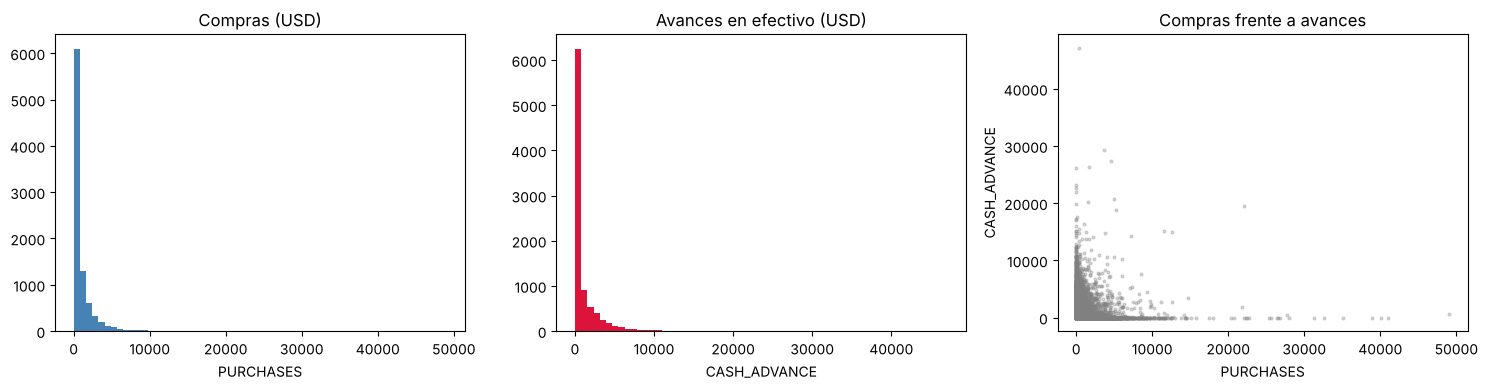

Clientes sin ninguna compra: 22.8%
Clientes sin avances en efectivo: 51.7%


In [5]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].hist(cc["PURCHASES"], bins=60, color="steelblue"); ax[0].set(title="Compras (USD)", xlabel="PURCHASES")
ax[1].hist(cc["CASH_ADVANCE"], bins=60, color="crimson"); ax[1].set(title="Avances en efectivo (USD)", xlabel="CASH_ADVANCE")
ax[2].scatter(cc["PURCHASES"], cc["CASH_ADVANCE"], s=4, alpha=0.3, color="gray")
ax[2].set(title="Compras frente a avances", xlabel="PURCHASES", ylabel="CASH_ADVANCE")
plt.tight_layout(); plt.show()
print("Clientes sin ninguna compra:", f"{(cc['PURCHASES'] == 0).mean():.1%}")
print("Clientes sin avances en efectivo:", f"{(cc['CASH_ADVANCE'] == 0).mean():.1%}")

**Interpretación.** Las dos distribuciones están amontonadas cerca de 0 con colas larguísimas: variables **muy asimétricas**. En el gráfico de la derecha casi todo el mundo queda en una esquina. Así, unos pocos clientes enormes dominarían cualquier distancia. Además, hay dos comportamientos: clientes que compran y clientes que usan avances.

# 3. Limpiar y preparar, paso a paso

**Paso 1: faltantes.** K-Means no puede medir distancias con datos faltantes.

In [6]:
print("Faltantes por columna:"); print(cc.isna().sum()[cc.isna().sum() > 0])
cc = cc.dropna(subset=["CREDIT_LIMIT"]).copy()                     # 1 cliente sin límite: lo quitamos
mediana_min = cc["MINIMUM_PAYMENTS"].median()
cc["MINIMUM_PAYMENTS"] = cc["MINIMUM_PAYMENTS"].fillna(mediana_min)  # 313 faltantes: los rellenamos con la mediana
print("Mediana usada para MINIMUM_PAYMENTS:", round(mediana_min, 1), "| Clientes que quedan:", len(cc))

Faltantes por columna:
CREDIT_LIMIT          1
MINIMUM_PAYMENTS    313
dtype: int64
Mediana usada para MINIMUM_PAYMENTS: 312.5 | Clientes que quedan: 8949


Eliminar los 313 clientes sería perder el 3,5 %; preferimos rellenar con la mediana y **declararlo**.

**Paso 2: escoger variables.** `CUST_ID` es un nombre, no un comportamiento. De las 17 restantes elegimos 9 que describen **cómo** se usa la tarjeta, evitando las que repiten casi lo mismo (por ejemplo, `PURCHASES_TRX` y `PURCHASES_FREQUENCY`).

In [7]:
VARS = ["BALANCE", "PURCHASES", "ONEOFF_PURCHASES", "INSTALLMENTS_PURCHASES", "CASH_ADVANCE",
        "PURCHASES_FREQUENCY", "CREDIT_LIMIT", "PAYMENTS", "PRC_FULL_PAYMENT"]
MONTOS = ["BALANCE", "PURCHASES", "ONEOFF_PURCHASES", "INSTALLMENTS_PURCHASES", "CASH_ADVANCE", "CREDIT_LIMIT", "PAYMENTS"]
cc[VARS].head()

,BALANCE,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,CREDIT_LIMIT,PAYMENTS,PRC_FULL_PAYMENT
0,40.900749,95.40,0.00,95.4,0.000000,0.166667,1000.0,201.802084,0.000000
1,3202.467416,0.00,0.00,0.0,6442.945483,0.000000,7000.0,4103.032597,0.222222
2,2495.148862,773.17,773.17,0.0,0.000000,1.000000,7500.0,622.066742,0.000000
3,1666.670542,1499.00,1499.00,0.0,205.788017,0.083333,7500.0,0.000000,0.000000
4,817.714335,16.00,16.00,0.0,0.000000,0.083333,1200.0,678.334763,0.000000


**Paso 3: el logaritmo para los montos.**

**¿Qué problema resuelve?** Mira estos cinco clientes y sus compras en 6 meses: 0, 10, 100, 1 000 y 10 000 USD. Si K-Means mide distancias con los dólares tal cual:

- entre el cliente de 0 y el de 1 000 hay 1 000 de distancia, y
- entre el de 1 000 y el de 10 000 hay 9 000.

Para K-Means, los cuatro primeros serían «casi iguales» y solo el de 10 000 sería distinto. Pero en la vida real no comprar nada y comprar 1 000 es una diferencia de comportamiento enorme. Además, en estos datos hay clientes de casi 50 000: unos pocos extremos que arrastrarían los centros hacia ellos.

**La solución: medir en «veces» en lugar de en dólares.** El logaritmo convierte multiplicaciones en sumas: cada vez que el monto se **multiplica por 10**, el logaritmo **sube lo mismo** (2,3). Así, pasar de 100 a 1 000 pesa lo mismo que pasar de 1 000 a 10 000: los dos son «10 veces más». Es como decir «gasta el doble» en lugar de «gasta 500 dólares más».

**¿Por qué $\log(1+x)$ y no $\log(x)$?** Porque muchos clientes tienen 0 compras y $\log(0)$ no existe. Sumando 1, el que no compra queda en $\log(1)=0$.

**¿A qué variables?** Solo a los **montos en dólares**. Las frecuencias y el porcentaje de pago total ya están entre 0 y 1 y no tienen valores extremos.

   compras_USD  log(1 + compras)  salto en USD  salto en log
0            0              0.00           NaN           NaN
1           10              2.40          10.0          2.40
2          100              4.62          90.0          2.22
3         1000              6.91         900.0          2.29
4        10000              9.21        9000.0          2.30


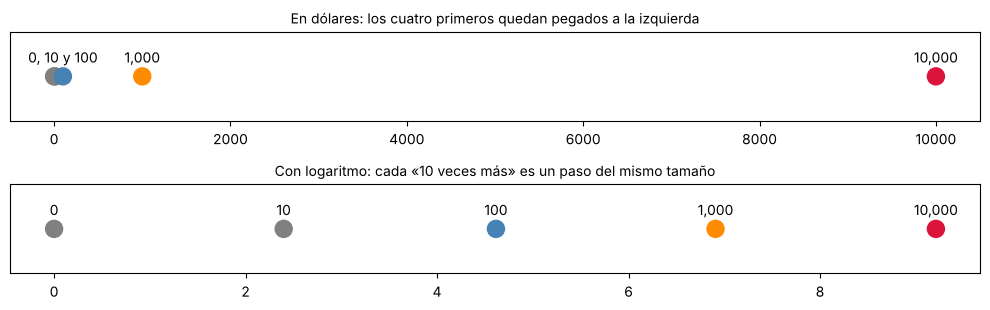

In [8]:
ejemplo = pd.DataFrame({"compras_USD": [0, 10, 100, 1000, 10000]})
ejemplo["log(1 + compras)"] = np.log1p(ejemplo["compras_USD"])       # np.log1p(x) calcula log(1 + x)
ejemplo["salto en USD"] = ejemplo["compras_USD"].diff()               # cuánto sube respecto al cliente anterior
ejemplo["salto en log"] = ejemplo["log(1 + compras)"].diff()
print(ejemplo.round(2))

fig, ax = plt.subplots(2, 1, figsize=(10, 3.2))
for i, (col, titulo) in enumerate([("compras_USD", "En dólares: los cuatro primeros quedan pegados a la izquierda"),
                                    ("log(1 + compras)", "Con logaritmo: cada «10 veces más» es un paso del mismo tamaño")]):
    ax[i].scatter(ejemplo[col], np.zeros(5), s=150, color=["gray", "gray", "steelblue", "darkorange", "crimson"])
    for x_, lab in zip(ejemplo[col], ejemplo["compras_USD"]):
        if i == 0 and lab in (0, 10):
            continue                                                   # en dólares 0, 10 y 100 se tapan: una sola etiqueta
        texto = "0, 10 y 100" if (i == 0 and lab == 100) else f"{lab:,}"
        ax[i].annotate(texto, (x_, 0), textcoords="offset points", xytext=(0, 10), ha="center")
    ax[i].set_yticks([]); ax[i].set_title(titulo, fontsize=10)
plt.tight_layout(); plt.show()

**Lee la tabla.** En dólares, los saltos crecen: 10, 90, 900, 9 000. Con logaritmo, cada salto es de ≈ 2,3, porque cada cliente gasta **10 veces más** que el anterior: el mismo «10 veces más» pesa lo mismo, sea de 100 a 1 000 o de 1 000 a 10 000. (El primer salto, de 0 a 10, es un poco mayor porque el 0 es especial: no comprar nada.) El orden se conserva: quien compra más sigue teniendo el número más alto.

Ahora lo aplicamos a los clientes reales, solo a los montos:

In [9]:
con_log = cc[VARS].copy()
con_log[MONTOS] = np.log1p(con_log[MONTOS])         # aplicar log(1 + x) solo a las 7 columnas de montos
print("Antes del logaritmo:"); print(cc[VARS].head(3).round(2))
print("\nDespués del logaritmo (las frecuencias y PRC_FULL_PAYMENT no cambian):"); print(con_log.head(3).round(2))

Antes del logaritmo:
   BALANCE  PURCHASES  ONEOFF_PURCHASES  INSTALLMENTS_PURCHASES  CASH_ADVANCE  PURCHASES_FREQUENCY  CREDIT_LIMIT  PAYMENTS  PRC_FULL_PAYMENT
0    40.90      95.40              0.00                    95.4          0.00                 0.17        1000.0    201.80              0.00
1  3202.47       0.00              0.00                     0.0       6442.95                 0.00        7000.0   4103.03              0.22
2  2495.15     773.17            773.17                     0.0          0.00                 1.00        7500.0    622.07              0.00

Después del logaritmo (las frecuencias y PRC_FULL_PAYMENT no cambian):


   BALANCE  PURCHASES  ONEOFF_PURCHASES  INSTALLMENTS_PURCHASES  CASH_ADVANCE  PURCHASES_FREQUENCY  CREDIT_LIMIT  PAYMENTS  PRC_FULL_PAYMENT
0     3.74       4.57              0.00                    4.57          0.00                 0.17          6.91      5.31              0.00
1     8.07       0.00              0.00                    0.00          8.77                 0.00          8.85      8.32              0.22
2     7.82       6.65              6.65                    0.00          0.00                 1.00          8.92      6.43              0.00


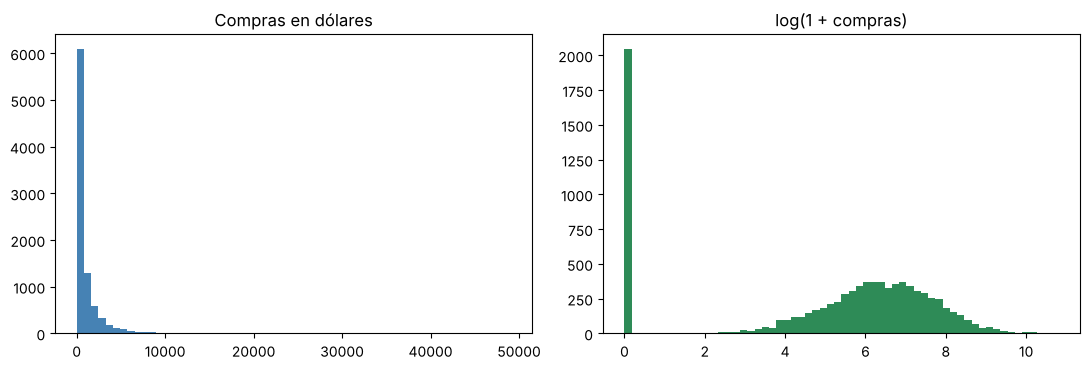

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].hist(cc["PURCHASES"], bins=60, color="steelblue"); ax[0].set_title("Compras en dólares")
ax[1].hist(con_log["PURCHASES"], bins=60, color="seagreen"); ax[1].set_title("log(1 + compras)")
plt.tight_layout(); plt.show()

**Interpretación.** A la izquierda casi todos los clientes se amontonan cerca de 0 y unos pocos llegan a 49 000. A la derecha se reparten de forma mucho más pareja; la barra en 0 son los clientes que no compran nada.

**Paso 4: estandarizar.** K-Means mide **distancias**, igual que KNN. Si no escalamos, el límite de crédito (miles) aplastaría a la frecuencia de compras (entre 0 y 1). Estandarizar: $z=(x-\text{media})/\text{desviación}$. Ejemplo con dos clientes que compran casi lo mismo pero con límites y frecuencias muy distintos:

In [11]:
a = {"PURCHASES": 1000, "CREDIT_LIMIT": 3000, "PURCHASES_FREQUENCY": 0.9}
b = {"PURCHASES": 1100, "CREDIT_LIMIT": 9000, "PURCHASES_FREQUENCY": 0.1}
desv = cc[list(a)].std()
for v in a:
    print(f"{v:20s} diferencia cruda {abs(a[v] - b[v]):8.1f} | diferencia en desviaciones {abs(a[v] - b[v]) / desv[v]:.2f}")

PURCHASES            diferencia cruda    100.0 | diferencia en desviaciones 0.05
CREDIT_LIMIT         diferencia cruda   6000.0 | diferencia en desviaciones 1.65
PURCHASES_FREQUENCY  diferencia cruda      0.8 | diferencia en desviaciones 1.99


Sin escalar, la diferencia de límite (6 000) domina y la de frecuencia (0,8) no cuenta, aunque un cliente compra todos los meses y el otro casi nunca. En desviaciones, la frecuencia (≈ 2) pesa tanto como el límite (≈ 1,6).

# 4. Dividir en Train y Validation

En clustering no hay respuesta que predecir, pero sí queremos saber si los grupos **se sostienen con clientes nuevos**. Aprendemos los grupos (y el logaritmo y el escalado) con Train y luego asignamos a los clientes de Validation al grupo más cercano. Si en Validation los grupos se ven igual de bien que en Train, la segmentación es confiable.

In [12]:
train_cc, val_cc = train_test_split(cc, test_size=0.30, random_state=42)     # 70 % Train, 30 % Validation
print("Train:", len(train_cc), "clientes | Validation:", len(val_cc), "clientes")

def preparar(df):
    # Paso 3: logaritmo de los montos (no aprende nada, se aplica igual a cualquier tabla)
    d = df[VARS].copy()
    d[MONTOS] = np.log1p(d[MONTOS])
    return d

escalador = StandardScaler().fit(preparar(train_cc))     # Paso 4: medias y desviaciones aprendidas SOLO con Train
X_train = escalador.transform(preparar(train_cc))
X_val = escalador.transform(preparar(val_cc))
print("\nMedia y desviación de las 3 primeras columnas en Train:", X_train.mean(axis=0)[:3].round(2), X_train.std(axis=0)[:3].round(2))
print("Media y desviación en Validation (casi 0 y 1):        ", X_val.mean(axis=0)[:3].round(2), X_val.std(axis=0)[:3].round(2))
print("\nAsí llegan los datos a K-Means (primeras filas de Train):")
pd.DataFrame(X_train, columns=VARS).head(3).round(2)

Train: 6264 clientes | Validation: 2685 clientes

Media y desviación de las 3 primeras columnas en Train: [-0. -0. -0.] [1. 1. 1.]
Media y desviación en Validation (casi 0 y 1):         [-0.01  0.03  0.02] [1.01 1.   1.01]

Así llegan los datos a K-Means (primeras filas de Train):


,BALANCE,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,CREDIT_LIMIT,PAYMENTS,PRC_FULL_PAYMENT
0,0.75,-1.67,-0.98,-1.09,1.74,-1.22,0.08,1.77,0.50
1,-1.53,0.31,-0.98,0.79,-0.94,-0.60,0.73,-1.07,-0.24
2,-1.54,0.09,-0.98,0.58,-0.94,0.64,-1.45,-0.86,2.90


In [13]:
# A mano, el primer cliente de Train en PURCHASES
x = preparar(train_cc)["PURCHASES"].iloc[0]
media, desviacion = escalador.mean_[1], escalador.scale_[1]
print(f"log(1 + compras) = {x:.3f} → z = ({x:.3f} − {media:.3f}) / {desviacion:.3f} = {(x - media) / desviacion:.3f}")
print("scikit-learn dice:", round(X_train[0, 1], 3))

log(1 + compras) = 0.000 → z = (0.000 − 4.878) / 2.918 = -1.671
scikit-learn dice: -1.671


# 5. K-Means a mano

**K-Means** divide los datos en `k` grupos. Cada grupo tiene un **centro** (el promedio de sus clientes) y cada cliente pertenece al grupo cuyo centro le queda más cerca. **K** es el número de grupos y **Means** significa *promedios*.

El algoritmo repite **dos pasos** hasta que nada cambia:

1. **Asignar:** cada cliente se va con el centro más cercano.
2. **Mover:** cada centro se muda al promedio de los clientes que le tocaron.

**Analogía.** Un banco quiere abrir 3 agencias. Las pone en cualquier lugar, cada cliente elige la agencia más cercana, luego cada agencia se muda al punto medio de sus clientes, los clientes vuelven a elegir… hasta que ninguna agencia necesita moverse.

**Ejemplo con 12 clientes y una sola variable: el gasto mensual** (20, 35, 40, 55, 300, 320, 350, 380, 900, 950, 1 000 y 1 100 USD).

**Cómo leer los gráficos:** cada punto es un cliente. **La altura es su gasto** (lo único que usa el modelo). De izquierda a derecha están ordenados de menor a mayor gasto, solo para verlos uno al lado del otro. El **color** de cada punto es el grupo que le tocó en esa vuelta. Las **líneas horizontales** del mismo color son los centros; las **flechas** a la derecha muestran a dónde se mueve cada centro; las **líneas negras punteadas** (último gráfico) son las fronteras entre grupos.

Empezamos, a propósito, con los tres centros mal ubicados: 20, 35 y 40.

In [14]:
gasto = np.array([20, 35, 40, 55, 300, 320, 350, 380, 900, 950, 1000, 1100], dtype=float)   # ordenados de menor a mayor
posicion = np.arange(1, 13)                                       # solo para dibujarlos uno al lado del otro
centros = np.array([20.0, 35.0, 40.0])                            # centros iniciales (mal ubicados a propósito)
historia = []                                                     # guardamos cada vuelta para dibujarla
for vuelta in range(1, 10):
    distancia = np.abs(gasto[:, None] - centros[None, :])         # distancia de cada cliente a cada centro (12 × 3)
    grupo = distancia.argmin(axis=1)                              # PASO 1, asignar: el centro más cercano
    nuevos = np.array([gasto[grupo == k].mean() for k in range(3)])   # PASO 2, mover: promedio de cada grupo
    historia.append((centros.copy(), grupo.copy(), nuevos.copy()))
    print(f"Vuelta {vuelta}: con centros {centros.round(1)} los grupos son {[gasto[grupo == k].astype(int).tolist() for k in range(3)]}")
    print(f"          → los centros se mueven a {nuevos.round(1)}")
    if np.allclose(nuevos, centros):
        print("Los centros ya no cambian: terminó.")
        break
    centros = nuevos

Vuelta 1: con centros [20. 35. 40.] los grupos son [[20], [35], [40, 55, 300, 320, 350, 380, 900, 950, 1000, 1100]]
          → los centros se mueven a [ 20.   35.  539.5]
Vuelta 2: con centros [ 20.   35.  539.5] los grupos son [[20], [35, 40, 55], [300, 320, 350, 380, 900, 950, 1000, 1100]]
          → los centros se mueven a [ 20.   43.3 662.5]
Vuelta 3: con centros [ 20.   43.3 662.5] los grupos son [[20], [35, 40, 55, 300, 320, 350], [380, 900, 950, 1000, 1100]]
          → los centros se mueven a [ 20.  183.3 866. ]
Vuelta 4: con centros [ 20.  183.3 866. ] los grupos son [[20, 35, 40, 55], [300, 320, 350, 380], [900, 950, 1000, 1100]]
          → los centros se mueven a [ 37.5 337.5 987.5]
Vuelta 5: con centros [ 37.5 337.5 987.5] los grupos son [[20, 35, 40, 55], [300, 320, 350, 380], [900, 950, 1000, 1100]]
          → los centros se mueven a [ 37.5 337.5 987.5]
Los centros ya no cambian: terminó.


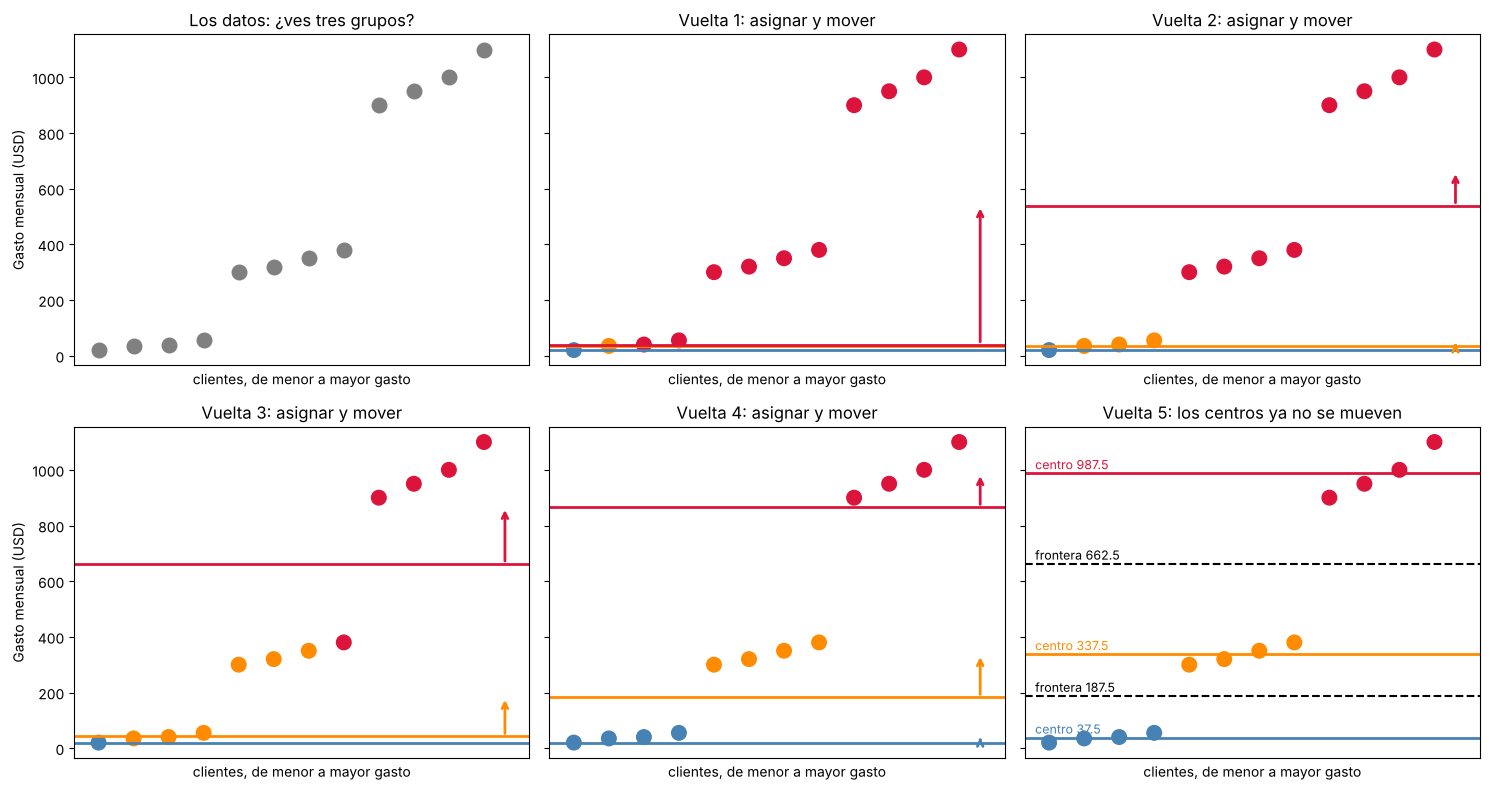

In [15]:
colores = np.array(["steelblue", "darkorange", "crimson"])
fig, ax = plt.subplots(2, 3, figsize=(15, 8), sharey=True)
ax = ax.ravel()
ax[0].scatter(posicion, gasto, s=110, color="gray")
ax[0].set_title("Los datos: ¿ves tres grupos?")
for i, (c_viejos, g, c_nuevos) in enumerate(historia[:5], start=1):
    ax[i].scatter(posicion, gasto, s=110, color=colores[g])                   # color = grupo asignado en esta vuelta
    for k in range(3):
        ax[i].axhline(c_viejos[k], color=colores[k], lw=2)                    # centro con el que se asignó
        if not np.isclose(c_viejos[k], c_nuevos[k]):
            ax[i].annotate("", xy=(12.6, c_nuevos[k]), xytext=(12.6, c_viejos[k]),
                           arrowprops=dict(arrowstyle="->", color=colores[k], lw=2))   # flecha: a dónde se mueve
    titulo = f"Vuelta {i}: asignar y mover" if i < len(historia) else f"Vuelta {i}: los centros ya no se mueven"
    ax[i].set_title(titulo)
final = historia[-1][0]
for f in (np.sort(final)[:-1] + np.sort(final)[1:]) / 2:
    ax[len(historia)].axhline(f, color="black", ls="--")
    ax[len(historia)].text(0.6, f + 15, f"frontera {f:.1f}", fontsize=9)
for k in range(3):
    ax[len(historia)].text(0.6, final[k] + 15, f"centro {final[k]:.1f}", color=colores[k], fontsize=9)
for a_ in ax:
    a_.set_xticks([]); a_.set_xlabel("clientes, de menor a mayor gasto"); a_.set_xlim(0.3, 13.3)   # espacio para las flechas
ax[0].set_ylabel("Gasto mensual (USD)"); ax[3].set_ylabel("Gasto mensual (USD)")
plt.tight_layout(); plt.show()

**Lee los gráficos, uno por uno.**

- **Vuelta 1:** los tres centros están abajo (20, 35 y 40). El de 40 es el más cercano para todos los clientes desde 40 hacia arriba, así que se queda con 10 clientes y su promedio es 539,5: la flecha muestra que ese centro **sube** a 539,5.
- **Vueltas 2 a 4:** con un centro ya arriba, los clientes se reparten de nuevo y los centros siguen moviéndose hacia el medio de cada franja.
- **Vuelta 5:** los centros (37,5; 337,5 y 987,5) ya no se mueven: **terminó**. Son los promedios de cada franja: $(20+35+40+55)/4=37{,}5$, $(300+320+350+380)/4=337{,}5$, $(900+950+1000+1100)/4=987{,}5$.
- **Las fronteras** son los puntos medios entre centros: $(37{,}5+337{,}5)/2=187{,}5$ y $(337{,}5+987{,}5)/2=662{,}5$. Un cliente que gasta menos de 187,5 va al grupo bajo; entre 187,5 y 662,5, al medio; más de 662,5, al alto.

# 6. K-Means simple con scikit-learn

Lo mismo que hicimos a mano, en **tres pasos**: crear, entrenar (`fit`) y ver los resultados. La diferencia con los modelos supervisados: `fit` recibe **solo X**, porque no hay respuesta `y`.

In [16]:
G = gasto.reshape(-1, 1)        # scikit-learn pide una TABLA (12 filas, 1 columna), no una lista

# 1) Crear el modelo: queremos 3 grupos
km_simple = KMeans(n_clusters=3, random_state=42, n_init=10)

# 2) Entrenar: hace las vueltas de "asignar y mover" que hicimos a mano. Solo recibe X
km_simple.fit(G)

# 3) Resultados
print("Centros encontrados (cluster_centers_):", km_simple.cluster_centers_.ravel().round(1))
print("Número de grupo de cada cliente (labels_):", km_simple.labels_)
print("Vueltas que necesitó (n_iter_):", km_simple.n_iter_)

Centros encontrados (cluster_centers_): [337.5 987.5  37.5]
Número de grupo de cada cliente (labels_): [2 2 2 2 0 0 0 0 1 1 1 1]
Vueltas que necesitó (n_iter_): 2


**Cuidado con los números de grupo.** `labels_` dice a qué grupo fue cada cliente, pero los números 0, 1 y 2 son **solo nombres**: no significa que el grupo 2 sea «mayor» que el 0. scikit-learn los numera en el orden en que aparecen. Para entenderlos, los ponemos en una tabla y les damos un nombre según su centro:

In [17]:
centros_sk = km_simple.cluster_centers_.ravel()
orden = np.argsort(centros_sk)                                         # del centro más bajo al más alto
nombre = {orden[0]: "gasto bajo", orden[1]: "gasto medio", orden[2]: "gasto alto"}
tabla_clientes = pd.DataFrame({"gasto": gasto.astype(int),
                               "grupo (labels_)": km_simple.labels_,
                               "centro de su grupo": centros_sk[km_simple.labels_].round(1),
                               "nombre": [nombre[g] for g in km_simple.labels_]})
tabla_clientes

,gasto,grupo (labels_),centro de su grupo,nombre
0,20,2,37.5,gasto bajo
1,35,2,37.5,gasto bajo
2,40,2,37.5,gasto bajo
3,55,2,37.5,gasto bajo
4,300,0,337.5,gasto medio
5,320,0,337.5,gasto medio
6,350,0,337.5,gasto medio
7,380,0,337.5,gasto medio
8,900,1,987.5,gasto alto
9,950,1,987.5,gasto alto


Los centros son los mismos que calculamos a mano. Ahora, **¿cómo se usa el modelo con clientes nuevos?** Con `predict`: mide la distancia del cliente a cada centro y lo asigna al más cercano.

In [18]:
nuevos_clientes = np.array([[50], [200], [500], [700], [1500]])        # gastos de 5 clientes nuevos
grupos_nuevos = km_simple.predict(nuevos_clientes)                     # el centro más cercano
dist = np.abs(nuevos_clientes - centros_sk[None, :])                   # distancia a cada centro, para verlo
resultado = pd.DataFrame(dist.round(1), columns=[f"distancia a {c:.1f}" for c in centros_sk])
resultado.insert(0, "gasto nuevo", nuevos_clientes.ravel())
resultado["grupo asignado"] = [nombre[g] for g in grupos_nuevos]
resultado

,gasto nuevo,distancia a 337.5,distancia a 987.5,distancia a 37.5,grupo asignado
0,50,287.5,937.5,12.5,gasto bajo
1,200,137.5,787.5,162.5,gasto medio
2,500,162.5,487.5,462.5,gasto medio
3,700,362.5,287.5,662.5,gasto alto
4,1500,1162.5,512.5,1462.5,gasto alto


El cliente de 500 está a 162,5 del centro medio y a 487,5 del alto: va al **gasto medio**. El de 700 queda más cerca del centro alto (287,5 frente a 362,5): **gasto alto**, porque pasó la frontera de 662,5.

# 7. Las métricas: a mano y con scikit-learn

**Inercia** = suma de las distancias al cuadrado de cada punto a su centro. Más baja = grupos más compactos.

**Silhouette** de un punto: $a$ = distancia media a los de su grupo; $b$ = distancia media al grupo vecino más cercano; $s=(b-a)/\max(a,b)$. Cerca de 1: bien ubicado; cerca de 0: en la frontera; negativo: probablemente en el grupo equivocado. El Silhouette del modelo es el **promedio** de todos los puntos.

A mano, con el cliente que gasta 55: está con 20, 35 y 40, así que $a=(35+20+15)/3=23{,}3$; su grupo vecino es el de 300 a 380: $b=(245+265+295+325)/4=282{,}5$; $s=(282{,}5-23{,}3)/282{,}5=0{,}92$.

In [19]:
etiquetas = km_simple.labels_
centro_de_cada = km_simple.cluster_centers_.ravel()[etiquetas]
inercia_mano = ((gasto - centro_de_cada) ** 2).sum()                 # suma de distancias al cuadrado
print(f"Inercia a mano: {inercia_mano:.1f} | scikit-learn (inertia_): {km_simple.inertia_:.1f}")

i55 = 3                                                              # posición del cliente que gasta 55
mismo = gasto[(etiquetas == etiquetas[i55]) & (np.arange(12) != i55)]
vecino = gasto[etiquetas == etiquetas[4]]                            # el grupo de 300 a 380
a_, b_ = np.abs(mismo - 55).mean(), np.abs(vecino - 55).mean()
print(f"Silhouette del cliente 55 a mano: a = {a_:.1f}, b = {b_:.1f}, s = {(b_ - a_) / max(a_, b_):.2f}")
print("Silhouette de cada cliente (scikit-learn):", silhouette_samples(G, etiquetas).round(2))
print("Silhouette promedio del modelo:", round(silhouette_score(G, etiquetas), 3))

Inercia a mano: 26175.0 | scikit-learn (inertia_): 26175.0
Silhouette del cliente 55 a mano: a = 23.3, b = 282.5, s = 0.92
Silhouette de cada cliente (scikit-learn): [0.93 0.96 0.96 0.92 0.81 0.87 0.88 0.83 0.79 0.86 0.87 0.8 ]
Silhouette promedio del modelo: 0.874


**Línea base: los cuartiles.** Una segmentación simple, sin Machine Learning: 4 grupos de 3 clientes según el gasto. Si K-Means no le gana, no vale la pena.

In [20]:
cuartiles = np.repeat([0, 1, 2, 3], 3)          # los 12 clientes ya están ordenados por gasto
print("Silhouette de cada cliente con cuartiles:", silhouette_samples(G, cuartiles).round(2))
print("Silhouette promedio — cuartiles:", round(silhouette_score(G, cuartiles), 3), "| K-Means:", round(silhouette_score(G, etiquetas), 3))

Silhouette de cada cliente con cuartiles: [ 0.91  0.95  0.93 -0.91  0.46  0.36 -0.57 -0.44 -0.78  0.75  0.84  0.78]
Silhouette promedio — cuartiles: 0.273 | K-Means: 0.874


Con cuartiles, el cliente de 55 queda con los de 300 y 320 y su Silhouette es **negativo** (−0,91): está en el grupo equivocado. K-Means sigue los huecos de los datos.

### Ahora con los clientes reales: Train frente a Validation

Entrenamos K-Means con `k = 4` en Train, asignamos los clientes de Validation con `predict` y comparamos: si el Silhouette y los tamaños se parecen, los grupos se sostienen con clientes nuevos.

In [21]:
km4 = KMeans(n_clusters=4, n_init=20, random_state=42).fit(X_train)       # aprender los grupos con Train
grupos_train = km4.labels_
grupos_val = km4.predict(X_val)                                           # asignar clientes nuevos al centro más cercano
print("Inercia en Train:", round(km4.inertia_))
print("Silhouette en Train:     ", round(silhouette_score(X_train, grupos_train, sample_size=4000, random_state=0), 3))
print("Silhouette en Validation:", round(silhouette_score(X_val, grupos_val), 3))
pd.DataFrame({"% clientes Train": pd.Series(grupos_train).value_counts(normalize=True).sort_index() * 100,
              "% clientes Validation": pd.Series(grupos_val).value_counts(normalize=True).sort_index() * 100}).round(1)

Inercia en Train: 28776


Silhouette en Train:      0.271
Silhouette en Validation: 0.268


,% clientes Train,% clientes Validation
0,14.0,14.7
1,27.5,26.4
2,31.5,31.1
3,26.9,27.7


**Interpretación.** El Silhouette y el porcentaje de clientes de cada grupo son casi iguales en Train y en Validation: los grupos **generalizan**. Un Silhouette de ≈ 0,27 indica grupos reales pero con fronteras difusas, algo normal en datos de comportamiento.

# 8. Los hiperparámetros de K-Means, uno por uno

Un **hiperparámetro** es una decisión que tomamos **antes** de entrenar; el modelo no la aprende solo. K-Means tiene cinco. Los vemos con los 12 clientes, donde se puede ver todo.

### `n_clusters` (k): cuántos grupos queremos

Es la decisión más importante. K-Means **siempre** entrega exactamente `k` grupos, aunque los datos no los tengan. Por defecto, scikit-learn usa 8. Veamos 2, 3 y 4 grupos:

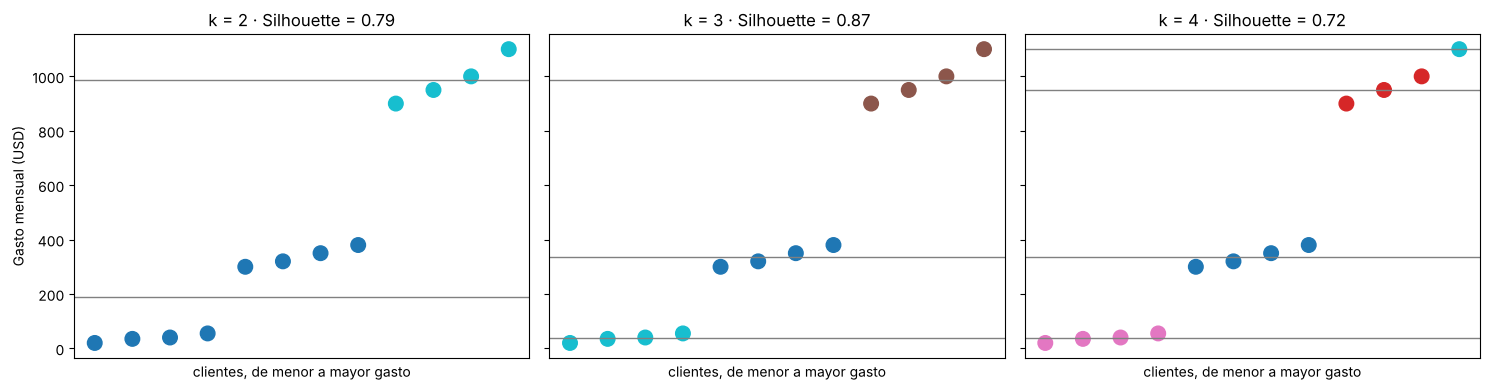

In [22]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for a_, k in zip(ax, [2, 3, 4]):
    m = KMeans(n_clusters=k, n_init=10, random_state=42).fit(G)          # mismo modelo, solo cambia k
    a_.scatter(posicion, gasto, s=110, c=m.labels_, cmap="tab10")
    for c_ in m.cluster_centers_.ravel(): a_.axhline(c_, color="gray", lw=1)
    a_.set_title(f"k = {k} · Silhouette = {silhouette_score(G, m.labels_):.2f}")
    a_.set_xticks([]); a_.set_xlabel("clientes, de menor a mayor gasto")
ax[0].set_ylabel("Gasto mensual (USD)"); plt.tight_layout(); plt.show()

Con **k = 2** junta a los de gasto bajo y medio. Con **k = 4** parte en dos un grupo que era uno solo. Con **k = 3** encuentra las tres franjas y tiene el Silhouette más alto. En datos reales no se ve a simple vista: por eso en la sección 9 probamos varios `k` con un `for`.

### `init`: dónde se ponen los centros al principio

- `"random"`: elige `k` clientes al azar y los usa como centros iniciales. Si salen dos centros en la misma franja, el resultado puede quedar mal.
- `"k-means++"` (por defecto): elige el primer centro al azar y los siguientes **lejos** de los que ya hay. Así casi nunca empieza mal.

### `n_init`: cuántas veces repetir todo desde inicios distintos

K-Means hace todo el proceso `n_init` veces, cada una con centros iniciales distintos, y **se queda con la de menor inercia** (los grupos más compactos). Es como tirar el dado varias veces y quedarte con el mejor resultado.

### `random_state`: la semilla del azar

Fija los «dados»: con el mismo número, el azar sale igual y obtenemos **exactamente** el mismo resultado cada vez que corremos la celda. Cualquier número sirve; usamos 42 por costumbre.

Veamos los tres juntos. Probamos 10 semillas con un solo intento (`n_init=1`) y comparamos los dos tipos de inicio:

In [23]:
filas = []
for semilla in range(10):
    al_azar = KMeans(n_clusters=3, init="random", n_init=1, random_state=semilla).fit(G)      # inicio al azar, 1 intento
    plus = KMeans(n_clusters=3, init="k-means++", n_init=1, random_state=semilla).fit(G)      # inicio separado, 1 intento
    azar_10 = KMeans(n_clusters=3, init="random", n_init=10, random_state=semilla).fit(G)    # inicio al azar, 10 intentos
    filas.append({"random_state": semilla,
                  "random, n_init=1 → centros": np.sort(al_azar.cluster_centers_.ravel()).round(1).tolist(),
                  "inercia": round(al_azar.inertia_),
                  "k-means++, n_init=1 → inercia": round(plus.inertia_),
                  "random, n_init=10 → inercia": round(azar_10.inertia_)})
pd.DataFrame(filas)

,random_state,"random, n_init=1 → centros",inercia,"k-means++, n_init=1 → inercia","random, n_init=10 → inercia"
0,0,"[37.5, 337.5, 987.5]",26175,26175,26175
1,1,"[37.5, 337.5, 987.5]",26175,26175,26175
2,2,"[37.5, 337.5, 987.5]",26175,26175,26175
3,3,"[37.5, 337.5, 987.5]",26175,26175,26175
4,4,"[187.5, 950.0, 1100.0]",189300,26175,26175
5,5,"[187.5, 950.0, 1100.0]",189300,26175,26175
6,6,"[187.5, 925.0, 1050.0]",190550,26175,26175
7,7,"[37.5, 337.5, 987.5]",26175,26175,26175
8,8,"[187.5, 950.0, 1100.0]",189300,26175,26175
9,9,"[37.5, 337.5, 987.5]",26175,26175,26175


**Lee la tabla.**

- Con `init="random"` y un solo intento, algunas semillas terminan mal: centros en 187,5, 950 y 1 100. Juntó a los grupos bajo y medio y partió en dos al alto. Su inercia es unas **7 veces mayor** (≈ 189 000 frente a 26 175). K-Means se quedó «atascado»: ningún centro tiene razón para moverse, pero la solución es mala.
- Con `"k-means++"` todas las semillas llegan a la buena solución.
- Con `n_init=10` también, aunque el inicio sea al azar: de 10 intentos, se queda con el mejor.
- Con la misma `random_state`, el resultado es siempre el mismo: por eso la fijamos.

### `max_iter`: cuántas vueltas como máximo

Es el límite de vueltas de «asignar y mover». Por defecto, 300; casi siempre termina mucho antes (nuestro ejemplo a mano terminó en 5). Si le damos los mismos centros iniciales del ejemplo (20, 35 y 40) y le permitimos **una sola vuelta**, se detiene a medio camino, igual que nuestra vuelta 1:

In [24]:
inicio = np.array([[20.0], [35.0], [40.0]])                                      # los centros iniciales del ejemplo a mano
una_vuelta = KMeans(n_clusters=3, init=inicio, n_init=1, max_iter=1).fit(G)
completo = KMeans(n_clusters=3, init=inicio, n_init=1, max_iter=300).fit(G)
print("max_iter=1   → centros:", una_vuelta.cluster_centers_.ravel().round(1), "(igual que la vuelta 1 a mano)")
print("max_iter=300 → centros:", completo.cluster_centers_.ravel().round(1), "| vueltas usadas:", completo.n_iter_)

max_iter=1   → centros: [ 20.   35.  539.5] (igual que la vuelta 1 a mano)
max_iter=300 → centros: [ 37.5 337.5 987.5] | vueltas usadas: 5


### Resumen

| Hiperparámetro | En palabras | Por defecto | Hoy usamos | Por qué |
|---|---|---|---|---|
| `n_clusters` | Cuántos grupos | 8 | 4 (clientes reales) | Se elige probando con un `for` (sección 9) |
| `init` | Dónde empiezan los centros | `"k-means++"` | `"k-means++"` | Empieza con centros separados |
| `n_init` | Cuántos intentos; se queda con el mejor | `"auto"` (1 con k-means++) | 20 | Evita quedar atascado en una mala solución |
| `max_iter` | Máximo de vueltas | 300 | 300 | Siempre termina antes |
| `random_state` | Semilla del azar | `None` (cambia cada vez) | 42 | Mismo resultado cada vez |

La **preparación de los datos** (qué variables usar, si aplicar logaritmo y escalar) no es un hiperparámetro de `KMeans`, pero cambia los grupos tanto como `k`. Por eso también la probamos en la sección 9.

### Lo mismo con los clientes reales

Con 6 264 clientes y 9 variables no podemos dibujarlo, pero sí ver la inercia. Con un intento al azar, algunas semillas quedan atascadas en soluciones peores; con 20 intentos, todas llegan a la misma:

In [25]:
filas = []
for semilla in range(6):
    m1 = KMeans(n_clusters=4, n_init=1, init="random", random_state=semilla).fit(X_train)    # un solo intento, inicio al azar
    m20 = KMeans(n_clusters=4, n_init=20, random_state=semilla).fit(X_train)                # veinte intentos
    filas.append({"random_state": semilla, "inercia con n_init=1": round(m1.inertia_), "inercia con n_init=20": round(m20.inertia_)})
pd.DataFrame(filas)

,random_state,inercia con n_init=1,inercia con n_init=20
0,0,29531,28776
1,1,28776,28776
2,2,29343,28776
3,3,28776,28776
4,4,28776,28776
5,5,28776,28776


**Interpretación.** Con un solo intento, las semillas 0 y 2 terminan con más inercia: grupos menos compactos, una solución peor. Con `n_init=20` todas llegan a la misma inercia. **Conclusión: usa varios intentos y fija `random_state`.**

# 9. Probar combinaciones con un `for`

Recorremos `k` de 2 a 8 con dos preparaciones (con y sin logaritmo) y medimos, en Train y en Validation, el Silhouette y el tamaño del grupo más chico. Incluimos la **línea base**: 4 grupos por cuartiles de compras.

In [26]:
X_train_sinlog = StandardScaler().fit(train_cc[VARS]).transform(train_cc[VARS])      # misma escala, sin logaritmo
esc_sinlog = StandardScaler().fit(train_cc[VARS]); X_val_sinlog = esc_sinlog.transform(val_cc[VARS])
filas = []
for nombre, Xtr, Xva in [("con log", X_train, X_val), ("sin log", X_train_sinlog, X_val_sinlog)]:
    for k in range(2, 9):
        m = KMeans(n_clusters=k, n_init=20, random_state=42).fit(Xtr)
        g_val = m.predict(Xva)
        filas.append({"preparación": nombre, "k": k, "inercia": round(m.inertia_),
                      "silhouette_train": silhouette_score(Xtr, m.labels_, sample_size=4000, random_state=0),
                      "silhouette_val": silhouette_score(Xva, g_val),
                      "grupo_mas_chico_%": 100 * np.bincount(m.labels_).min() / len(m.labels_)})
rejilla = pd.DataFrame(filas).round(3)
base_q = pd.qcut(train_cc["PURCHASES"].rank(method="first"), 4, labels=False)        # línea base en Train
print("Línea base (cuartiles de compras) → Silhouette en Train:", round(silhouette_score(X_train, base_q, sample_size=4000, random_state=0), 3))
rejilla

Línea base (cuartiles de compras) → Silhouette en Train: 0.139


,preparación,k,inercia,silhouette_train,silhouette_val,grupo_mas_chico_%
0,con log,2,40567,0.278,0.273,33.525
1,con log,3,33213,0.263,0.263,30.699
2,con log,4,28776,0.271,0.268,14.033
3,con log,5,25614,0.270,0.271,12.723
4,con log,6,23223,0.282,0.282,3.464
5,con log,7,21423,0.274,0.275,3.257
6,con log,8,19972,0.239,0.237,3.033
7,sin log,2,45475,0.475,0.475,13.458
8,sin log,3,38653,0.382,0.350,4.949
9,sin log,4,32287,0.268,0.272,1.325


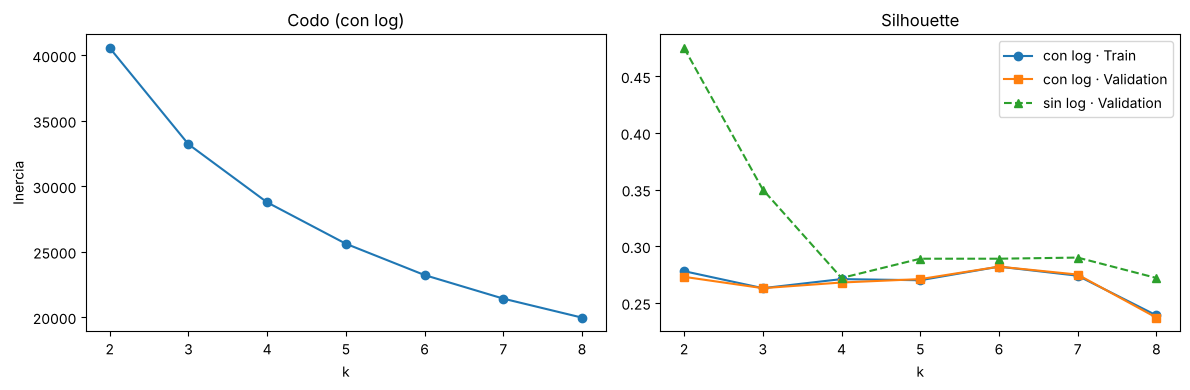

In [27]:
con, sin = rejilla[rejilla["preparación"] == "con log"], rejilla[rejilla["preparación"] == "sin log"]
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(con["k"], con["inercia"], marker="o"); ax[0].set(title="Codo (con log)", xlabel="k", ylabel="Inercia")
ax[1].plot(con["k"], con["silhouette_train"], marker="o", label="con log · Train")
ax[1].plot(con["k"], con["silhouette_val"], marker="s", label="con log · Validation")
ax[1].plot(sin["k"], sin["silhouette_val"], marker="^", ls="--", label="sin log · Validation")
ax[1].set(title="Silhouette", xlabel="k"); ax[1].legend()
plt.tight_layout(); plt.show()

**Lee los resultados con cuidado.**

- **Línea base:** Silhouette ≈ 0,14. Cualquier K-Means con logaritmo la duplica.
- **Sin logaritmo, k = 2 tiene el Silhouette más alto (≈ 0,47).** Parece la mejor opción, pero su grupo más chico es de solo 13 %: separa a los clientes «grandes» (saldo, límite y pagos altos) del resto. Es obvio e inútil. Y con k ≥ 4 sin logaritmo aparecen grupos de menos del 2 %: unos pocos clientes extremos. **Un Silhouette alto no basta: mira los tamaños.**
- **Con logaritmo**, el Silhouette queda entre 0,24 y 0,28 para todos los `k`, casi igual en Train y en Validation: los grupos se sostienen con clientes nuevos.
- **k = 6 con logaritmo tiene el Silhouette más alto (0,28)**, pero su grupo más chico es de 3,5 %: descartado por la misma razón.
- **k = 2 con logaritmo (0,28)** solo separa «compra» de «no compra»: demasiado grueso para decidir campañas.
- **El codo:** la inercia baja mucho hasta k = 4 y luego cada grupo extra aporta menos.
- **Elegimos k = 4 con logaritmo:** Silhouette casi igual al mejor (0,27 frente a 0,28), el doble de la línea base, igual en Validation, todos los grupos con más del 10 % de clientes y, como veremos, perfiles que se pueden explicar.

# 10. Modelo final: describir los grupos

In [28]:
kmeans_final = KMeans(n_clusters=4, n_init=20, random_state=42).fit(X_train)
train_cc = train_cc.assign(segmento=kmeans_final.labels_)
print("Clientes de Train por segmento:"); print(train_cc["segmento"].value_counts().sort_index())
train_cc.groupby("segmento")[VARS].median().round(2).T             # medianas en unidades originales

Clientes de Train por segmento:
segmento
0     879
1    1725
2    1973
3    1687
Name: count, dtype: int64


segmento,0,1,2,3
BALANCE,88.24,1457.38,1877.42,120.63
PURCHASES,928.53,0.00,1199.77,283.30
ONEOFF_PURCHASES,95.00,0.00,695.90,0.00
INSTALLMENTS_PURCHASES,469.89,0.00,355.80,126.48
CASH_ADVANCE,0.00,1242.65,148.68,0.00
PURCHASES_FREQUENCY,0.92,0.00,0.83,0.50
CREDIT_LIMIT,4000.00,3000.00,6000.00,1800.00
PAYMENTS,1077.06,797.03,1660.24,338.41
PRC_FULL_PAYMENT,0.83,0.00,0.00,0.00


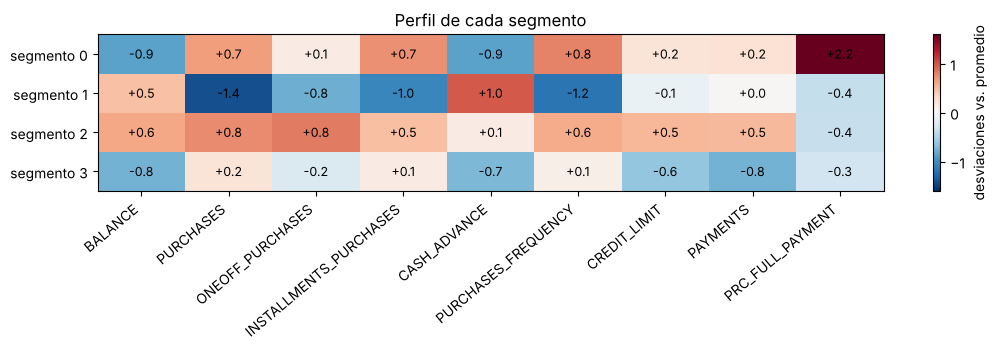

In [29]:
perfil = pd.DataFrame(X_train, columns=VARS).groupby(kmeans_final.labels_).mean()   # promedio de cada segmento en z
fig, ax = plt.subplots(figsize=(11, 3.6))
im = ax.imshow(perfil.values, cmap="RdBu_r", vmin=-1.6, vmax=1.6, aspect="auto")
ax.set_xticks(range(len(VARS))); ax.set_xticklabels(VARS, rotation=40, ha="right")
ax.set_yticks(range(4)); ax.set_yticklabels([f"segmento {k}" for k in range(4)])
for i in range(4):
    for j in range(len(VARS)):
        ax.text(j, i, f"{perfil.values[i, j]:+.1f}", ha="center", va="center", fontsize=9)
plt.colorbar(im, ax=ax, label="desviaciones vs. promedio"); plt.title("Perfil de cada segmento"); plt.tight_layout(); plt.show()

**Cómo leer el mapa de calor.** Rojo: el segmento está por encima del promedio en esa variable; azul: por debajo. Leemos fila por fila y ponemos un nombre que describa el comportamiento. Los números de segmento son etiquetas arbitrarias. Con estos datos aparecen cuatro perfiles:

| Perfil | Lo que lo distingue | Idea de uso |
|---|---|---|
| **Compradores que financian** | Saldo alto, compran mucho y seguido, límite alto, casi nunca pagan el total | Ofertas de cuotas; vigilar el endeudamiento |
| **Totaleros** | Saldo muy bajo, compran casi todos los meses, pagan el total la mayoría de los meses | Programas de recompensas; bajo riesgo |
| **Usuarios de avances en efectivo** | Casi no compran y usan avances en efectivo; saldo alto | Posible necesidad de liquidez: revisar riesgo y ofrecer otros productos |
| **Poco activos** | Saldo, compras, pagos y límite bajos | Campañas de activación |

**Cuidado.** Los grupos describen comportamiento de 6 meses según **nuestras** variables. No prueban causas ni son categorías oficiales; con otras variables saldrían otros grupos.

## 10.1 Ponerle nombre a cada segmento

Los números 0, 1, 2 y 3 son etiquetas arbitrarias: si cambia la semilla, el «segmento 0» puede llamarse «2». Para no depender del número, ponemos el nombre **con una regla** basada en el mapa de calor:

1. el segmento con el `PRC_FULL_PAYMENT` más alto son los **totaleros**;
2. de los que quedan, el de `CASH_ADVANCE` más alto son los **usuarios de avances**;
3. de los que quedan, el de `PURCHASES` más alto son los **compradores que financian**;
4. el que sobra son los **poco activos**.

In [30]:
pendientes = list(perfil.index)                         # segmentos aún sin nombre
NOMBRES = {}
for variable, nombre in [("PRC_FULL_PAYMENT", "Totaleros"), ("CASH_ADVANCE", "Usuarios de avances"),
                         ("PURCHASES", "Compradores que financian")]:
    seg = perfil.loc[pendientes, variable].idxmax()     # el más alto en esa variable, entre los que faltan
    NOMBRES[seg] = nombre
    pendientes.remove(seg)
NOMBRES[pendientes[0]] = "Poco activos"                 # el que sobra
for seg in sorted(NOMBRES):
    print(f"segmento {seg} → {NOMBRES[seg]:26s} ({(kmeans_final.labels_ == seg).sum()} clientes de Train)")

segmento 0 → Totaleros                  (879 clientes de Train)
segmento 1 → Usuarios de avances        (1725 clientes de Train)
segmento 2 → Compradores que financian  (1973 clientes de Train)
segmento 3 → Poco activos               (1687 clientes de Train)


## 10.2 Un cliente nuevo: ¿a qué segmento pertenece? (K-Means)

Llega un cliente nuevo con sus datos de 6 meses. Para saber su segmento hay que hacerle **exactamente la misma preparación** que a los clientes de Train y luego medir su distancia a los 4 centros:

| Paso | Qué hacemos | Código |
|---|---|---|
| 1 | Escribir sus datos en dólares, con las mismas 9 variables | `pd.DataFrame(...)` |
| 2 | Logaritmo de los montos | `preparar(...)` |
| 3 | Estandarizar con la media y desviación **de Train** (no se vuelve a ajustar) | `escalador.transform(...)` |
| 4 | Distancia a cada uno de los 4 centros | `kmeans_final.transform(...)` |
| 5 | Elegir el centro más cercano | `kmeans_final.predict(...)` |

Probamos con tres clientes inventados:

In [31]:
# Paso 1: los datos tal como los veríamos en el banco (dólares y proporciones)
nuevos = pd.DataFrame([
    # BALANCE, PURCHASES, ONEOFF, INSTALLMENTS, CASH_ADVANCE, PURCH_FREQ, CREDIT_LIMIT, PAYMENTS, PRC_FULL_PAYMENT
    [  2500,       0,        0,       0,         3000,        0.0,        4000,        900,      0.0],   # Ana
    [    50,     800,      200,     600,            0,        1.0,        5000,        850,      1.0],   # Beto
    [   150,     100,        0,     100,            0,        0.3,        1500,        200,      0.0]],  # Carla
    columns=VARS, index=["Ana", "Beto", "Carla"])
print("Paso 1, datos originales:"); print(nuevos); print()

Z_nuevos = escalador.transform(preparar(nuevos))        # pasos 2 y 3: log de montos + escalado de Train
print("Pasos 2 y 3, ya preparados (desviaciones):"); print(pd.DataFrame(Z_nuevos, columns=VARS, index=nuevos.index).round(2)); print()

distancias = kmeans_final.transform(Z_nuevos)           # paso 4: distancia a cada centro
tabla_dist = pd.DataFrame(distancias.round(2), index=nuevos.index,
                          columns=[f"dist. a {NOMBRES[s]}" for s in range(4)])
tabla_dist["segmento asignado"] = [NOMBRES[s] for s in kmeans_final.predict(Z_nuevos)]   # paso 5: el más cercano
tabla_dist

Paso 1, datos originales:
       BALANCE  PURCHASES  ONEOFF_PURCHASES  INSTALLMENTS_PURCHASES  CASH_ADVANCE  PURCHASES_FREQUENCY  CREDIT_LIMIT  PAYMENTS  PRC_FULL_PAYMENT
Ana       2500          0                 0                       0          3000                  0.0          4000       900               0.0
Beto        50        800               200                     600             0                  1.0          5000       850               1.0
Carla      150        100                 0                     100             0                  0.3          1500       200               0.0

Pasos 2 y 3, ya preparados (desviaciones):
       BALANCE  PURCHASES  ONEOFF_PURCHASES  INSTALLMENTS_PURCHASES  CASH_ADVANCE  PURCHASES_FREQUENCY  CREDIT_LIMIT  PAYMENTS  PRC_FULL_PAYMENT
Ana       0.82      -1.67             -0.98                   -1.09          1.31                -1.22          0.24      0.11             -0.52
Beto     -1.12       0.62              0.65                 

,dist. a Totaleros,dist. a Usuarios de avances,dist. a Compradores que financian,dist. a Poco activos,segmento asignado
Ana,5.38,0.70,4.08,3.92,Usuarios de avances
Beto,1.13,5.80,3.98,3.94,Totaleros
Carla,3.67,3.26,3.43,1.14,Poco activos


**Lee la tabla.** Cada fila es un cliente nuevo y cada columna su distancia a uno de los 4 centros. El segmento asignado es la columna con el número **más pequeño**. Ana no compra y saca efectivo: queda más cerca del centro de **usuarios de avances**. Beto compra todos los meses y paga el total: **totaleros**. Carla usa poco la tarjeta: **poco activos**.

Si la distancia al segundo centro más cercano es casi igual a la del primero, el cliente está **en la frontera** entre dos segmentos (su Silhouette sería cercano a 0): conviene tratarlo con cuidado.


# 11. Clustering jerárquico

## 11.1 A mano

El clustering **jerárquico aglomerativo** empieza con cada fila como su propio grupo y en cada paso **une los dos grupos más cercanos**, hasta que queda uno solo. El **dendrograma** dibuja esas uniones; el número de grupos se elige **cortándolo** con una línea horizontal. No hay que decidir `k` al inicio y siempre da el mismo resultado, pero es lento con muchos datos porque compara todos los pares.

Cinco clientes en una recta: A = 1, B = 2, C = 6, D = 7, E = 15. Matriz de distancias:

| | A = 1 | B = 2 | C = 6 | D = 7 | E = 15 |
|---|---:|---:|---:|---:|---:|
| A | — | **1** | 5 | 6 | 14 |
| B | | — | 4 | 5 | 13 |
| C | | | — | **1** | 9 |
| D | | | | — | 8 |

| Paso | Distancia menor | Se unen | Centro del grupo nuevo |
|---|---|---|---|
| 1 | 1 (A-B) | A y B | 1,5 |
| 2 | 1 (C-D) | C y D | 6,5 |
| 3 | 6,5 − 1,5 = 5 | {A, B} y {C, D} | 4 |
| 4 | 15 − 4 = 11 | {A, B, C, D} y E | — |

Cortar a altura 3 deja 3 grupos ({A, B}, {C, D}, {E}); a altura 8 deja 2 ({A, B, C, D}, {E}).

Uniones [grupo 1, grupo 2, distancia, tamaño]:
[[ 0.  1.  1.  2.]
 [ 2.  3.  1.  2.]
 [ 5.  6.  5.  4.]
 [ 4.  7. 11.  5.]]


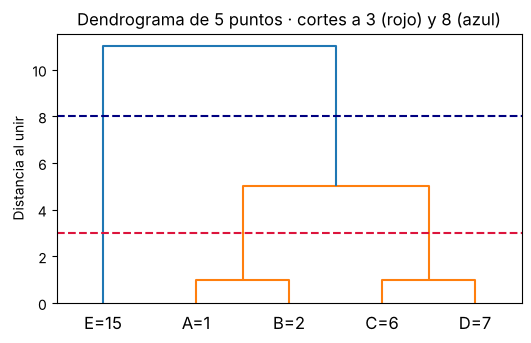

In [32]:
recta5 = np.array([[1], [2], [6], [7], [15]], dtype=float)
Z5 = linkage(recta5, method="centroid")        # cada fila de Z5: qué grupos se unen y a qué distancia
print("Uniones [grupo 1, grupo 2, distancia, tamaño]:"); print(Z5.round(2))
plt.figure(figsize=(6, 3.5))
dendrogram(Z5, labels=["A=1", "B=2", "C=6", "D=7", "E=15"])
plt.axhline(3, color="crimson", ls="--"); plt.axhline(8, color="navy", ls="--")
plt.title("Dendrograma de 5 puntos · cortes a 3 (rojo) y 8 (azul)"); plt.ylabel("Distancia al unir"); plt.show()

## 11.2 El modelo simple con scikit-learn

In [33]:
jer_simple = AgglomerativeClustering(n_clusters=2, linkage="ward")   # 1) crear: 2 grupos, regla de unión Ward
grupos5 = jer_simple.fit_predict(recta5)                              # 2) y 3) unir y devolver el grupo de cada punto
print("Grupo de A, B, C, D y E:", grupos5)
print("Silhouette:", round(silhouette_score(recta5, grupos5), 3))

Grupo de A, B, C, D y E: [0 0 0 0 1]
Silhouette: 0.518


Igual que cortar a altura 8: {A, B, C, D} y {E}. El jerárquico **no tiene `predict`**: para un cliente nuevo hay que volver a construir el árbol. Por eso se usa con pocos datos o con una muestra.

## 11.3 Los hiperparámetros del jerárquico

| Hiperparámetro | Qué controla | Valor por defecto |
|---|---|---|
| `n_clusters` | Cuántos grupos quedan al cortar el árbol | 2 |
| `linkage` | Cómo se mide la distancia entre dos grupos: `"ward"` (la unión que menos aumenta la variación interna), `"complete"` (puntos más lejanos), `"average"` (promedio), `"single"` (puntos más cercanos) | `"ward"` |
| `metric` | Cómo se mide la distancia entre dos puntos (Ward solo admite euclidiana) | `"euclidean"` |
| `distance_threshold` | En lugar de `n_clusters`: cortar el árbol a una altura dada | `None` |

## 11.4 Con los clientes reales: dendrograma y `for` con las reglas de unión

Usamos una muestra de 2 000 clientes de Train, ya preparados (logaritmo y escalado).

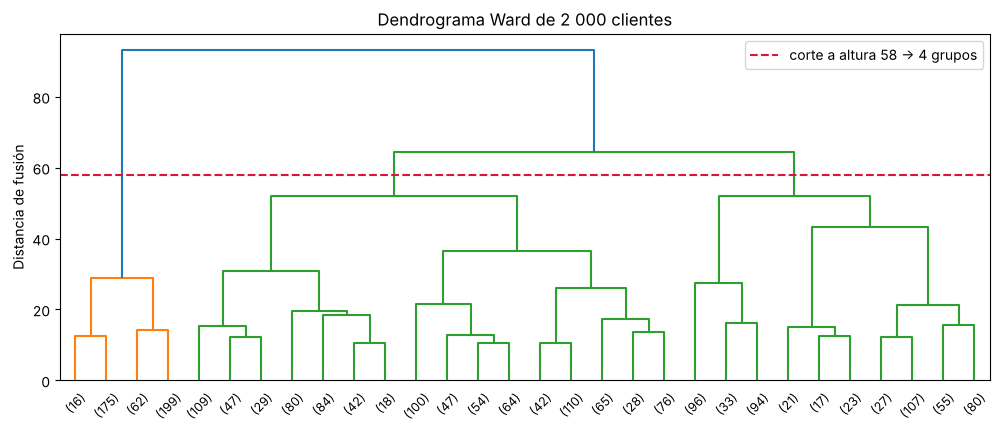

In [34]:
rng = np.random.RandomState(42)
idx = rng.choice(len(X_train), 2000, replace=False)    # 2 000 clientes de Train al azar (siempre los mismos)
X_muestra = X_train[idx]
Z_ward = linkage(X_muestra, method="ward")              # todas las uniones: 1 999 filas [grupo, grupo, altura, tamaño]
plt.figure(figsize=(12, 4.5))
dendrogram(Z_ward, truncate_mode="lastp", p=30, leaf_font_size=9)   # solo las últimas 30 ramas
plt.axhline(58, color="crimson", ls="--", label="corte a altura 58 → 4 grupos")
plt.title("Dendrograma Ward de 2 000 clientes"); plt.ylabel("Distancia de fusión"); plt.legend(); plt.show()

**Cómo leer el dendrograma, despacio.**

- **Abajo** hay 30 ramas. El número entre paréntesis, por ejemplo **(143)**, es cuántos clientes hay en esa rama.
- **Cada línea horizontal** es una unión de dos grupos. Su **altura** dice qué tan distintos eran: mientras más arriba, más distintos.
- **Para elegir el número de grupos**, se traza una línea horizontal donde las líneas verticales son más largas (un gran salto sin uniones). **El número de líneas verticales que corta es el número de grupos.** La línea roja corta 4.

Veamos las alturas exactas de las últimas uniones y qué grupos quedan con cada corte:

In [35]:
from scipy.cluster.hierarchy import fcluster       # corta el árbol en k grupos
alturas = Z_ward[-6:, 2][::-1]                      # las 6 últimas uniones, de la más alta a la más baja
print("Altura de las últimas uniones:", alturas.round(1))
filas = []
for k in [2, 3, 4, 5, 6]:
    g = fcluster(Z_ward, k, criterion="maxclust")   # cortar el árbol para que queden k grupos
    filas.append({"grupos": k, "se corta debajo de la altura": round(Z_ward[-(k - 1), 2], 1),
                  "tamaños": sorted(np.bincount(g)[1:].tolist(), reverse=True),
                  "silhouette": round(silhouette_score(X_muestra, g), 3)})
pd.DataFrame(filas)

Altura de las últimas uniones: [93.1 64.4 52.  51.9 43.3 36.5]


,grupos,se corta debajo de la altura,tamaños,silhouette
0,2,93.1,"[1548, 452]",0.255
1,3,64.4,"[995, 553, 452]",0.234
2,4,52.0,"[995, 452, 330, 223]",0.247
3,5,51.9,"[586, 452, 409, 330, 223]",0.252
4,6,43.3,"[586, 452, 409, 269, 223, 61]",0.261


**Interpretación.**

- La última unión ocurre a altura ≈ 93 y la anterior a ≈ 64: es el **salto más grande**. La separación más fuerte de los datos es en **2 grupos**: unos 450 clientes que casi no compran y usan avances en efectivo, frente a todos los demás.
- Para 4 y 5 grupos las uniones están casi a la misma altura (≈ 52): el árbol no distingue bien entre 4 y 5. Elegimos 4 para comparar con K-Means.
- El Silhouette queda entre 0,23 y 0,26 con cualquier corte: grupos reales pero con fronteras difusas, como en K-Means.

Ahora probamos las cuatro reglas de unión con un `for`:

In [36]:
filas = []
for regla in ["ward", "complete", "average", "single"]:
    for k in [3, 4, 5]:
        g = AgglomerativeClustering(n_clusters=k, linkage=regla).fit_predict(X_muestra)
        filas.append({"linkage": regla, "k": k, "silhouette": silhouette_score(X_muestra, g),
                      "tamaños": sorted(np.bincount(g).tolist(), reverse=True),
                      "grupo_mas_chico_%": 100 * np.bincount(g).min() / len(g),
                      "ARI vs K-Means": adjusted_rand_score(kmeans_final.labels_[idx], g) if k == 4 else np.nan})
pd.DataFrame(filas).round(3)

,linkage,k,silhouette,tamaños,grupo_mas_chico_%,ARI vs K-Means
0,ward,3,0.234,"[995, 553, 452]",22.60,NaN
1,ward,4,0.247,"[995, 452, 330, 223]",11.15,0.487
2,ward,5,0.252,"[586, 452, 409, 330, 223]",11.15,NaN
3,complete,3,0.129,"[1272, 665, 63]",3.15,NaN
4,complete,4,0.219,"[824, 665, 448, 63]",3.15,0.394
5,complete,5,0.218,"[824, 561, 448, 104, 63]",3.15,NaN
6,average,3,0.233,"[1936, 61, 3]",0.15,NaN
7,average,4,0.174,"[1929, 61, 7, 3]",0.15,0.003
8,average,5,0.083,"[1926, 61, 7, 3, 3]",0.15,NaN
9,single,3,0.243,"[1992, 7, 1]",0.05,NaN


**Interpretación.** *Average* y *single* tienen Silhouette parecido o mayor que Ward, pero mira los tamaños: dejan casi todos los clientes en un grupo y aíslan unos pocos casos extremos. Para segmentar son inútiles (sirven, en cambio, para encontrar casos raros). **Ward** da grupos equilibrados y, con k = 4, coincide moderadamente con K-Means (ARI ≈ 0,5): encuentran una estructura parecida, no idéntica.

## 11.5 Interpretar los 4 grupos de Ward

Igual que con K-Means: calculamos el perfil de cada grupo y le ponemos nombre. Además, contamos cuántos clientes de cada grupo de Ward cayeron en cada segmento de K-Means.

In [37]:
ward4 = AgglomerativeClustering(n_clusters=4, linkage="ward").fit_predict(X_muestra)   # 4 grupos de la muestra
perfil_ward = pd.DataFrame(X_muestra, columns=VARS).groupby(ward4).mean()             # promedio de cada grupo (desviaciones)
perfil_ward.insert(0, "clientes", np.bincount(ward4))
print("Perfil de cada grupo de Ward (desviaciones respecto al promedio):")
print(perfil_ward.round(1)); print()

km_nombres = pd.Series(kmeans_final.labels_[idx]).map(NOMBRES).values                 # segmento K-Means de los mismos clientes
cruce = pd.crosstab(pd.Series(ward4, name="grupo Ward"), pd.Series(km_nombres, name="segmento K-Means"))
print("¿Cuántos clientes de cada grupo de Ward están en cada segmento de K-Means?")
cruce

Perfil de cada grupo de Ward (desviaciones respecto al promedio):
   clientes  BALANCE  PURCHASES  ONEOFF_PURCHASES  INSTALLMENTS_PURCHASES  CASH_ADVANCE  PURCHASES_FREQUENCY  CREDIT_LIMIT  PAYMENTS  PRC_FULL_PAYMENT
0       995      0.3        0.5               0.7                     0.1           0.1                  0.2           0.1       0.2              -0.4
1       452      0.5       -1.7              -1.0                    -1.1           1.0                 -1.2          -0.1       0.1              -0.4
2       330     -0.9        0.1              -0.8                     0.5          -0.7                  0.3          -0.3      -1.1              -0.2
3       223     -0.9        0.7               0.2                     0.7          -0.9                  0.8           0.1       0.2               2.4

¿Cuántos clientes de cada grupo de Ward están en cada segmento de K-Means?


segmento K-Means,Compradores que financian,Poco activos,Totaleros,Usuarios de avances
grupo Ward,,,,
0,606,267,18,104
1,0,2,1,449
2,16,280,21,13
3,1,0,222,0


**Cómo leer las dos tablas.**

- **El perfil** se lee igual que el mapa de calor de K-Means: positivo = por encima del promedio, negativo = por debajo. Busca en cada fila el número más extremo.
- **El cruce** muestra, en cada fila, en qué segmento de K-Means cayeron los clientes de ese grupo de Ward. Si casi todos caen en una sola columna, los dos métodos encontraron **el mismo grupo**.

Con estos datos:

| Grupo de Ward | Lo que lo distingue | En K-Means es… |
|---|---|---|
| ≈ 450 clientes | Compras muy bajas (≈ −1,7), saldo alto, no paga el total | **Usuarios de avances**: casi todos coinciden |
| ≈ 220 clientes | Pago total muy alto (≈ +2,4), saldo muy bajo | **Totaleros**: casi todos coinciden |
| ≈ 330 clientes | Saldo y pagos bajos | Sobre todo **poco activos** |
| ≈ 1 000 clientes | Compras algo altas, no paga el total | **Mezcla**: compradores que financian, parte de los poco activos y algunos de avances |

**Conclusión.** Dos métodos distintos encuentran los mismos dos perfiles más claros (avances y totaleros): es una buena señal de que esos grupos existen de verdad. La diferencia está en el grupo grande de Ward, que K-Means divide entre «compradores que financian» y «poco activos». Por eso el ARI es ≈ 0,5 y no 1.

## 11.6 Un cliente nuevo en el jerárquico

El jerárquico **no tiene `predict`**: el árbol se construyó con esos 2 000 clientes y no tiene «centros» guardados. Hay dos formas de ubicar a un cliente nuevo:

1. **Por el centro de cada grupo (la más usada).** Calculamos el promedio de cada grupo de Ward (su «centro», como en K-Means) y asignamos al cliente al más cercano. Es rápido.
2. **Rehaciendo el árbol con el cliente incluido.** Agregamos al cliente a los 2 000, volvemos a unir todo y miramos en qué grupo quedó. Es exacto pero lento: hay que repetirlo por cada cliente nuevo.

Usamos los mismos tres clientes, **ya preparados** con el logaritmo y el escalado de Train (`Z_nuevos`).

In [38]:
# Forma 1: centro de cada grupo de Ward y el más cercano
centros_ward = pd.DataFrame(X_muestra).groupby(ward4).mean().values                 # 4 centros (promedios en desviaciones)
dist_ward = np.sqrt(((Z_nuevos[:, None, :] - centros_ward[None, :, :]) ** 2).sum(axis=2))   # distancia a cada centro
nombre_ward = {g: cruce.loc[g].idxmax() for g in cruce.index}     # nombre de cada grupo = segmento K-Means que más coincide
t1 = pd.DataFrame(dist_ward.round(2), index=nuevos.index, columns=[f"dist. a grupo {g} ({nombre_ward[g]})" for g in range(4)])
t1["grupo (forma 1)"] = [nombre_ward[g] for g in dist_ward.argmin(axis=1)]

# Forma 2: rehacer el árbol con cada cliente nuevo incluido
forma2 = []
for i in range(len(Z_nuevos)):
    X_con_nuevo = np.vstack([X_muestra, Z_nuevos[i]])                                # 2 001 clientes
    g = AgglomerativeClustering(n_clusters=4, linkage="ward").fit_predict(X_con_nuevo)
    companeros = ward4[g[:-1] == g[-1]]                     # los clientes que quedaron en su mismo grupo
    forma2.append(nombre_ward[np.bincount(companeros).argmax()])   # su grupo original más común
t1["grupo (forma 2)"] = forma2
t1["K-Means"] = tabla_dist["segmento asignado"]
t1

,dist. a grupo 0 (Compradores que financian),dist. a grupo 1 (Usuarios de avances),dist. a grupo 2 (Poco activos),dist. a grupo 3 (Totaleros),grupo (forma 1),grupo (forma 2),K-Means
Ana,3.56,0.58,4.13,5.50,Usuarios de avances,Usuarios de avances,Usuarios de avances
Beto,4.00,5.99,3.93,1.01,Totaleros,Totaleros,Totaleros
Carla,2.75,3.44,1.16,3.79,Poco activos,Poco activos,Poco activos


**Lee la tabla.** Las primeras columnas son la distancia de cada cliente al centro de cada grupo de Ward; el grupo asignado es la más pequeña. La forma 2 muestra dónde quedó cada cliente al rehacer el árbol, y la última columna repite lo que dijo K-Means. Si las tres columnas coinciden, el cliente tiene un perfil claro.

**En resumen:**

| | K-Means | Jerárquico |
|---|---|---|
| ¿Tiene `predict`? | Sí: distancia a los centros aprendidos | No |
| Cliente nuevo | `escalador.transform` → `kmeans.predict` | Centro de cada grupo + el más cercano, o rehacer el árbol |
| ¿Cuándo usarlo? | Muchos clientes y asignación diaria | Pocos datos, o para **ver** la estructura con el dendrograma |


# 12. Comparación final: todos los métodos en todos los datasets del día

Hoy usamos tres «datasets»: los **12 clientes** del ejemplo, los clientes reales con **una sola variable** (log de compras) y los clientes reales con **las 9 variables**. Aplicamos a cada uno la línea base y todos los métodos con el mismo número de grupos, y medimos:

- **Silhouette** (más alto = grupos más separados) y
- **tamaño del grupo más chico** (%): si es menor a 5 %, el método solo está aislando casos raros.

Regla para escoger: **el mayor Silhouette entre los métodos cuyo grupo más chico tiene al menos 5 %**. Para que todos se midan igual, en los datos reales usamos la misma muestra de 2 000 clientes.

In [39]:
una_var = escalador.transform(preparar(train_cc))[:, [VARS.index("PURCHASES")]]   # log de compras, escalado
datasets = {"12 clientes (gasto)": (G, 3, cuartiles),
            "Clientes · solo compras": (una_var[idx], 3, pd.qcut(pd.Series(una_var[idx, 0]).rank(method="first"), 3, labels=False).values),
            "Clientes · 9 variables": (X_muestra, 4, pd.qcut(train_cc["PURCHASES"].iloc[idx].rank(method="first"), 4, labels=False).values)}
metodos = {"K-Means": lambda k: KMeans(n_clusters=k, n_init=20, random_state=42),
           "Jerárquico Ward": lambda k: AgglomerativeClustering(n_clusters=k, linkage="ward"),
           "Jerárquico complete": lambda k: AgglomerativeClustering(n_clusters=k, linkage="complete"),
           "Jerárquico average": lambda k: AgglomerativeClustering(n_clusters=k, linkage="average"),
           "Jerárquico single": lambda k: AgglomerativeClustering(n_clusters=k, linkage="single")}
filas = []
for nombre_ds, (Xd, k, base) in datasets.items():
    filas.append({"dataset": nombre_ds, "método": "Línea base (cuantiles)", "k": len(np.unique(base)),
                  "silhouette": silhouette_score(Xd, base), "grupo_mas_chico_%": 100 * np.bincount(base).min() / len(base)})
    for nombre_m, crear in metodos.items():
        g = crear(k).fit_predict(Xd)
        filas.append({"dataset": nombre_ds, "método": nombre_m, "k": k,
                      "silhouette": silhouette_score(Xd, g), "grupo_mas_chico_%": 100 * np.bincount(g).min() / len(g)})
comparacion = pd.DataFrame(filas).round(3)
comparacion

,dataset,método,k,silhouette,grupo_mas_chico_%
0,12 clientes (gasto),Línea base (cuantiles),4,0.273,25.000
1,12 clientes (gasto),K-Means,3,0.874,33.333
2,12 clientes (gasto),Jerárquico Ward,3,0.874,33.333
3,12 clientes (gasto),Jerárquico complete,3,0.874,33.333
4,12 clientes (gasto),Jerárquico average,3,0.874,33.333
5,12 clientes (gasto),Jerárquico single,3,0.874,33.333
6,Clientes · solo compras,Línea base (cuantiles),3,0.535,33.300
7,Clientes · solo compras,K-Means,3,0.653,23.900
8,Clientes · solo compras,Jerárquico Ward,3,0.653,23.650
9,Clientes · solo compras,Jerárquico complete,3,0.550,8.900


In [40]:
print("Silhouette (filas: método, columnas: dataset):")
print(comparacion.pivot(index="método", columns="dataset", values="silhouette").round(3))
print()
for nombre_ds in datasets:
    validos = comparacion[(comparacion["dataset"] == nombre_ds) & (comparacion["grupo_mas_chico_%"] >= 5)]
    g = validos.sort_values("silhouette", ascending=False).iloc[0]
    print(f"{nombre_ds:25s} → gana {g['método']:22s} (Silhouette {g['silhouette']:.3f}, grupo más chico {g['grupo_mas_chico_%']:.1f} %)")

Silhouette (filas: método, columnas: dataset):
dataset                 12 clientes (gasto)  Clientes · 9 variables  Clientes · solo compras
método                                                                                      
Jerárquico Ward                       0.874                   0.247                    0.653
Jerárquico average                    0.874                   0.174                    0.591
Jerárquico complete                   0.874                   0.219                    0.550
Jerárquico single                     0.874                   0.233                    0.666
K-Means                               0.874                   0.266                    0.653
Línea base (cuantiles)                0.273                   0.138                    0.535

12 clientes (gasto)       → gana K-Means                (Silhouette 0.874, grupo más chico 33.3 %)
Clientes · solo compras   → gana K-Means                (Silhouette 0.653, grupo más chico 23.9 %)
Clientes ·

### ¿Por qué gana un método distinto en cada caso?

- **12 clientes:** los grupos son tres franjas muy separadas; todos los métodos encuentran exactamente las mismas franjas (Silhouette cercano a 0,9). La línea base de cuartiles, que corta sin mirar los huecos, queda muy abajo.
- **Clientes, solo compras:** con una variable, los grupos son tramos de una recta; K-Means y Ward los dibujan casi igual (0,653). *Single* tiene un Silhouette apenas mayor (0,666), pero su grupo más chico es el 0,1 % de los clientes: aísla unos pocos extremos y queda descartado por tamaño, igual que *average*.
- **Clientes, 9 variables:** los grupos son difusos (Silhouette ≈ 0,2–0,3). Entre los métodos con grupos de tamaño útil gana K-Means (0,266), seguido de Ward (0,247). Con miles de clientes, **K-Means** es además el práctico: es rápido y puede asignar clientes nuevos con `predict`.

**Lecciones:**

1. **Siempre compara con una línea base sencilla.** Si el modelo no le gana, no aporta.
2. **El Silhouette solo no basta:** mira los tamaños. Un método que aísla 3 clientes raros puede tener buen Silhouette y no servir para segmentar.
3. **Comprueba en Validation** que los grupos se sostienen con clientes nuevos.
4. **Describe los grupos** en unidades originales y con nombres de comportamiento: es lo que vuelve útil un clustering.

# Actividad autónoma

1. Quita el logaritmo y repite el modelo final con k = 4. ¿Qué perfiles cambian? ¿Cuál solución explicarías mejor a un gerente?
2. Agrega `CASH_ADVANCE_FREQUENCY` y `MINIMUM_PAYMENTS` a `VARS`. ¿Aparece un segmento nuevo con k = 5? ¿Se sostiene en Validation?
3. Cambia la línea base: cuartiles de `BALANCE` en lugar de `PURCHASES`. ¿K-Means sigue ganando?
4. En la sección 11.4, prueba `linkage="ward"` con k = 6. ¿Cómo cambian los tamaños?
5. Escribe en 150 palabras qué acción comercial o de riesgo propondrías para el segmento de avances en efectivo, y qué dato adicional pedirías antes de aplicarla.